# Regression — Implementation Cheatsheet

Theory: [regression.md](regression.md) · Metrics: [evaluation_metrics.md](../01_toolkit/evaluation_metrics.md#1-regression-predicting-a-number)

**Dataset:** SuperKart: 8,763 product × store rows. **Target:** `Product_Store_Sales_Total` (revenue of a product in a store).

| # | Section |
|---|---|
| 1 | Setup & data |
| 2 | Cleaning & feature engineering |
| 3 | Quick EDA (target + relations) |
| 4 | Encoding & train/test split |
| 5 | Multicollinearity (VIF) |
| 6 | Linear Regression with statsmodels (OLS): p-values, coefficients |
| 7 | Checking the linear regression assumptions |
| 8 | sklearn models: Linear, Ridge, Lasso, Tree, Random Forest, Gradient Boosting |
| 9 | Cross-validation & tuning |
| 10 | Feature importance & conclusion |

## 1. Setup & data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

import warnings
warnings.filterwarnings("ignore")   # keeps the cheatsheet readable (VIF on redundant columns warns a lot)

pd.set_option("display.max_columns", None)
SEED = 0
TARGET = "Product_Store_Sales_Total"

In [2]:
data = pd.read_csv("../data/superkart.csv")
print(data.shape)
data.head()

(8763, 12)


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


## 2. Cleaning & feature engineering

In [3]:
df = data.copy()

# Fix inconsistent labels: 'reg' and 'Regular' are the same category
df["Product_Sugar_Content"] = df["Product_Sugar_Content"].replace("reg", "Regular")

# Product_Id is unique per row (useless as is), but its first 2 letters are a category:
# FD = food, DR = drinks, NC = non-consumable
df["Product_Id"] = df["Product_Id"].str[:2]

# Year -> age: easier for the model and for people to read
df["Store_Age"] = 2023 - df["Store_Establishment_Year"]
df = df.drop(columns="Store_Establishment_Year")

# Reduce 16 product types to 2 business groups
perishables = ["Fruits and Vegetables", "Dairy", "Meat", "Breads", "Breakfast", "Seafood"]
df["Perishable"] = df["Product_Type"].isin(perishables).astype(int)
df = df.drop(columns="Product_Type")

print(df.isna().sum().sum(), "missing |", df.duplicated().sum(), "duplicates")
df.head()

0 missing | 0 duplicates


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Id,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Store_Age,Perishable
0,FD,12.66,Low Sugar,0.027,117.08,OUT004,Medium,Tier 2,Supermarket Type2,2842.40,14,0
1,FD,16.54,Low Sugar,0.144,171.43,OUT003,Medium,Tier 1,Departmental Store,4830.02,24,1
2,FD,14.28,Regular,0.031,162.08,OUT001,High,Tier 2,Supermarket Type1,4130.16,36,0
3,FD,12.10,Low Sugar,0.112,186.31,OUT001,High,Tier 2,Supermarket Type1,4132.18,36,0
4,NC,9.57,No Sugar,0.010,123.67,OUT002,Small,Tier 3,Food Mart,2279.36,25,0


## 3. Quick EDA

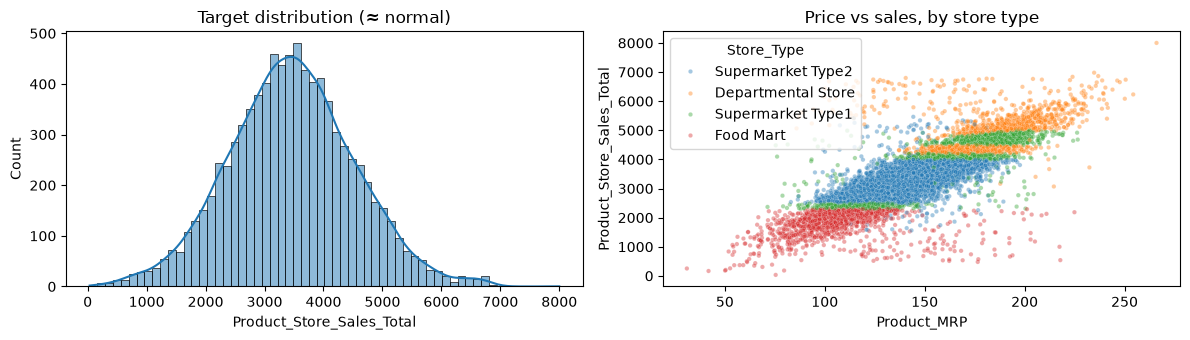

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df[TARGET], kde=True, ax=ax[0]).set_title("Target distribution (≈ normal)")
sns.scatterplot(data=df, x="Product_MRP", y=TARGET, hue="Store_Type", alpha=.4, s=10, ax=ax[1])
ax[1].set_title("Price vs sales, by store type")
plt.tight_layout(); plt.show()

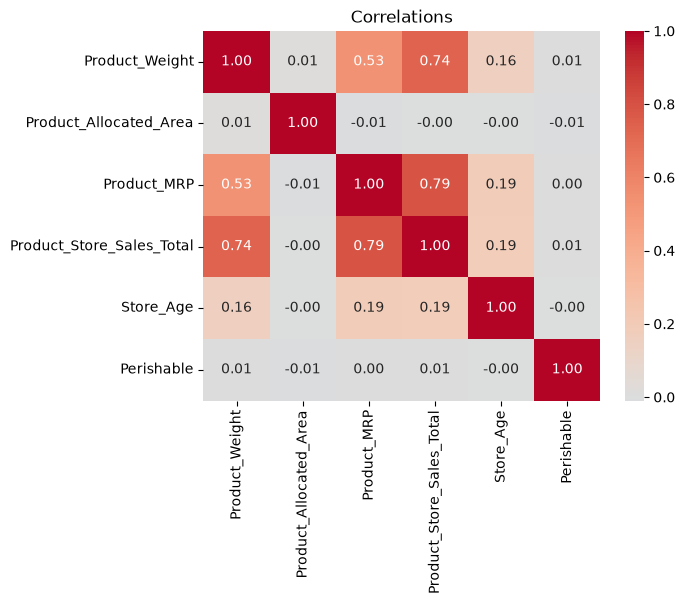

In [5]:
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations"); plt.show()

In [6]:
# Each store has exactly one type, size, city tier and age.
# These 5 columns carry the SAME information, which leads to multicollinearity (see section 5)
df.groupby("Store_Id")[["Store_Type", "Store_Size", "Store_Location_City_Type", "Store_Age"]].first()

,Store_Type,Store_Size,Store_Location_City_Type,Store_Age
Store_Id,,,,
OUT001,Supermarket Type1,High,Tier 2,36
OUT002,Food Mart,Small,Tier 3,25
OUT003,Departmental Store,Medium,Tier 1,24
OUT004,Supermarket Type2,Medium,Tier 2,14


## 4. Encoding & train/test split
- `drop_first=True` avoids the **dummy variable trap** (one dummy is always predictable from the others).
- Split **before** any fitting so the test set stays unseen.

In [7]:
cat_cols = df.select_dtypes(["object", "string"]).columns.tolist()
df_ohe = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

X = df_ohe.drop(columns=TARGET)
y = df_ohe[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_train.shape, X_test.shape

((6134, 19), (2629, 19))

## 5. Multicollinearity (VIF)
**VIF** (Variance Inflation Factor) measures how well one feature is predicted by the others.
1 = none · > 5 = high · **inf = perfectly redundant**. It mainly matters for **linear models**, because it makes coefficients and p-values unreliable.

In [8]:
def vif_table(X):
    Xc = sm.add_constant(X.astype(float))
    return (pd.DataFrame({"feature": Xc.columns,
                          "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
            .query("feature != 'const'")
            .sort_values("VIF", ascending=False))

vif_table(X_train).head(8)

,feature,VIF
10,Store_Id_OUT002,1.000800e+15
7,Product_Id_NC,1.000800e+15
4,Store_Age,1.000800e+15
16,Store_Location_City_Type_Tier 3,1.000800e+15
17,Store_Type_Food Mart,1.000800e+15
18,Store_Type_Supermarket Type1,1.000800e+15
8,Product_Sugar_Content_No Sugar,1.000800e+15
11,Store_Id_OUT003,1.000800e+15


The huge values (~10¹⁵, which in practice means infinite) come from:
- **Store columns**: `Store_Id`, `Store_Type`, `Store_Size`, city tier and `Store_Age` all identify the same 4 stores, so we keep **only `Store_Type`**.
- **`Product_Id_NC` = `No Sugar`**: every non-consumable has "No Sugar", so we keep `Product_Id_NC`.

In [9]:
redundant = [c for c in X.columns if c.startswith(("Store_Id_", "Store_Size_", "Store_Location_City_Type_"))]
redundant += ["Store_Age", "Product_Sugar_Content_No Sugar"]

X_train = X_train.drop(columns=redundant)
X_test = X_test.drop(columns=redundant)
vif_table(X_train)

,feature,VIF
8,Store_Type_Food Mart,3.607617
10,Store_Type_Supermarket Type2,3.270556
5,Product_Id_FD,2.841545
6,Product_Id_NC,2.691809
9,Store_Type_Supermarket Type1,1.983011
3,Product_MRP,1.932903
1,Product_Weight,1.790910
4,Perishable,1.222380
7,Product_Sugar_Content_Regular,1.086384
2,Product_Allocated_Area,1.001068


## 6. Linear Regression with statsmodels (OLS)
`statsmodels` gives the **statistics** (p-values, confidence intervals, R²) and `sklearn` gives the **ML workflow**. Use statsmodels when you need to *explain* the model.

In [10]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                                OLS Regression Results                               
Dep. Variable:     Product_Store_Sales_Total   R-squared:                       0.821
Model:                                   OLS   Adj. R-squared:                  0.821
Method:                        Least Squares   F-statistic:                     2806.
Date:                       Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                               15:59:52   Log-Likelihood:                -46211.
No. Observations:                       6134   AIC:                         9.244e+04
Df Residuals:                           6123   BIC:                         9.252e+04
Df Model:                                 10                                         
Covariance Type:                   nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------

**Drop non-significant features** (p-value > 0.05) one at a time, highest first, because removing one changes the others' p-values.

In [11]:
cols = X_train.columns.tolist()
while True:
    model = sm.OLS(y_train, sm.add_constant(X_train[cols])).fit()
    pvals = model.pvalues.drop("const")
    if pvals.max() <= 0.05:
        break
    print(f"drop {pvals.idxmax():35s} p = {pvals.max():.3f}")
    cols.remove(pvals.idxmax())

ols_final = model
print(f"\nKept {len(cols)} features | Adj. R² = {ols_final.rsquared_adj:.3f}")

drop Product_Allocated_Area              p = 0.633
drop Product_Id_NC                       p = 0.365
drop Product_Sugar_Content_Regular       p = 0.115
drop Perishable                          p = 0.051
drop Product_Id_FD                       p = 0.101

Kept 5 features | Adj. R² = 0.820


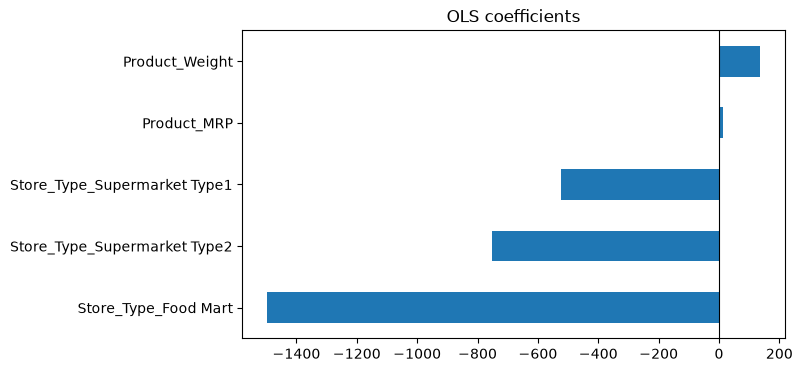

In [12]:
# Coefficient = change in sales when the feature goes up by 1 (others fixed)
ols_final.params.drop("const").sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("OLS coefficients"); plt.axvline(0, color="k", lw=.8); plt.show()

## 7. Checking the linear regression assumptions
| Assumption | Check | OK if |
|---|---|---|
| Mean of residuals = 0 | `resid.mean()` | ≈ 0 |
| Linearity | residuals vs fitted plot | no pattern |
| Homoscedasticity (constant variance) | same plot + **Goldfeld-Quandt** test | no funnel shape, p > 0.05 |
| Normal residuals | histogram + **Q-Q plot** | points follow the line |
| No multicollinearity | VIF | < 5 (done in section 5) |

Mean of residuals: 2.23e-12
Goldfeld-Quandt p-value: 0.998 -> homoscedastic ✅


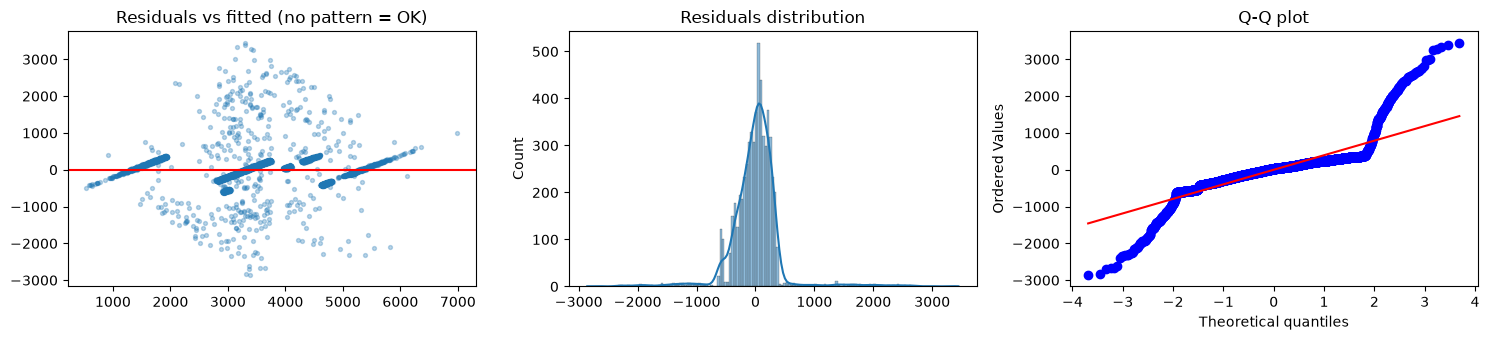

In [13]:
resid, fitted = ols_final.resid, ols_final.fittedvalues
print(f"Mean of residuals: {resid.mean():.2e}")

gq_pvalue = sms.het_goldfeldquandt(resid, sm.add_constant(X_train[cols]))[1]
print(f"Goldfeld-Quandt p-value: {gq_pvalue:.3f} -> {'homoscedastic ✅' if gq_pvalue > 0.05 else 'heteroscedastic ❌'}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].scatter(fitted, resid, alpha=.3, s=8); ax[0].axhline(0, color="r")
ax[0].set_title("Residuals vs fitted (no pattern = OK)")
sns.histplot(resid, kde=True, ax=ax[1]).set_title("Residuals distribution")
stats.probplot(resid, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q plot")
plt.tight_layout(); plt.show()

## 8. sklearn models
Same features and the same split for all models. Linear models get **scaled** inputs (needed for Ridge/Lasso penalties); tree models don't need scaling.

In [14]:
def evaluate(model, X, y):
    y_hat = model.predict(X)
    return {"RMSE": mean_squared_error(y, y_hat) ** 0.5,
            "MAE": mean_absolute_error(y, y_hat),
            "MAPE": mean_absolute_percentage_error(y, y_hat),
            "R2": r2_score(y, y_hat)}

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (L2)":        make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (L1)":        make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
    "Decision Tree":     DecisionTreeRegressor(random_state=SEED),
    "Random Forest":     RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    tr, te = evaluate(m, X_train, y_train), evaluate(m, X_test, y_test)
    rows.append({"model": name, "train_R2": tr["R2"], "test_R2": te["R2"],
                 "test_RMSE": te["RMSE"], "test_MAE": te["MAE"], "test_MAPE": te["MAPE"]})

results = pd.DataFrame(rows).set_index("model").round(3).sort_values("test_RMSE")
results

,train_R2,test_R2,test_RMSE,test_MAE,test_MAPE
model,,,,,
Random Forest,0.989,0.935,268.842,100.484,0.037
Gradient Boosting,0.891,0.881,365.014,161.735,0.057
Decision Tree,1.000,0.876,371.953,129.654,0.047
Lasso (L1),0.821,0.833,432.711,250.988,0.096
Linear Regression,0.821,0.832,432.788,252.636,0.096
Ridge (L2),0.821,0.832,432.789,252.536,0.096


**How to read it**
- **train R² ≫ test R²** means overfitting. The **Decision Tree** is the classic example (train R² ≈ 1).
- If a simple linear model is close to the ensembles, prefer it: easier to explain and to deploy.

## 9. Cross-validation & tuning
One train/test split can be lucky or unlucky. **K-fold CV** gives a mean ± std.

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name in ["Linear Regression", "Random Forest", "Gradient Boosting"]:
    scores = -cross_val_score(models[name], X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    cv_rows.append({"model": name, "CV_RMSE_mean": scores.mean(), "CV_RMSE_std": scores.std()})
pd.DataFrame(cv_rows).set_index("model").round(1)

,CV_RMSE_mean,CV_RMSE_std
model,,
Linear Regression,453.2,27.7
Random Forest,300.6,21.9
Gradient Boosting,381.2,21.7


In [16]:
# Hyperparameter tuning: GridSearchCV = try every combination with CV
param_grid = {"n_estimators": [100, 300], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}
grid = GridSearchCV(GradientBoostingRegressor(random_state=SEED), param_grid,
                    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

print("Best params:", grid.best_params_)
pd.DataFrame([evaluate(grid.best_estimator_, X_test, y_test)], index=["Tuned GB (test)"]).round(3)

Best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}


,RMSE,MAE,MAPE,R2
Tuned GB (test),277.059,116.563,0.042,0.931


## 10. Feature importance & conclusion

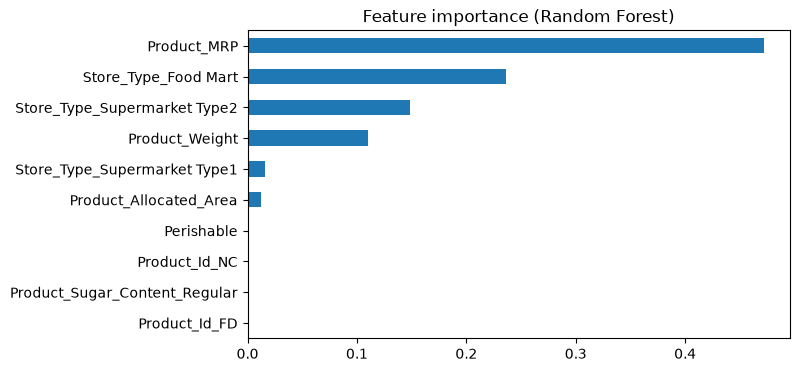

Product_MRP                      0.472
Store_Type_Food Mart             0.236
Store_Type_Supermarket Type2     0.148
Product_Weight                   0.110
Store_Type_Supermarket Type1     0.016
Product_Allocated_Area           0.012
Perishable                       0.002
Product_Id_NC                    0.001
Product_Sugar_Content_Regular    0.001
Product_Id_FD                    0.001
dtype: float64

In [17]:
importance = pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind="barh", figsize=(7, 4), title="Feature importance (Random Forest)")
plt.show()
importance.sort_values(ascending=False).round(3)

**Conclusions**
- **Best model: Random Forest** (test R² ≈ 0.93, MAPE ≈ 4%). Tuning took Gradient Boosting from R² 0.88 to 0.93, almost the same as Random Forest.
- **Linear regression** (R² ≈ 0.83, MAPE ≈ 10%) **meets all the assumptions** and is fully explainable, which makes it the baseline to beat.
- Ridge and Lasso ≈ plain linear: with only ~10 non-redundant features there is nothing to regularize.
- **Price (`Product_MRP`)** is the main driver (~47% of importance), followed by **store type** (~40% combined) and product weight (~11%). Sugar content, allocated area and perishability barely matter.
- Fix redundant columns (VIF) **before** reading linear coefficients; otherwise they are meaningless.